# 01 - Área de estudo e grelha comum

| | |
|---|---|
| **Tarefa do plano** | S1-03 - definir a área de estudo (bacia + Marracuene) e a projeção EPSG:32736 |
| **Variáveis (Parte I)** | #1 bacia do Incomáti, #2 distrito de Marracuene |
| **Fonte** | HydroBASINS e FAO GAUL 2015, via Earth Engine |
| **Saída** | `data/raw/aoi/` |

Ficheiros criados:

- `marracuene_district.geojson` - área-alvo dos alertas
- `incomati_basin.geojson` - bacia completa do Incomáti (todas as unidades HydroBASINS que partilham a mesma foz)
- `incomati_lower_subbasin.geojson` - a unidade de nível 6 que contém Marracuene
- `aoi.geojson` - **AOI das imagens**: retângulo envolvente do distrito + margem, usado para todos os dados de 10-30 m
- `aoi_climate.geojson` - retângulo envolvente da bacia + margem, usado para os dados de baixa resolução (chuva, humidade do solo, caudal)
- `grid.json` - a grelha de píxeis de 30 m em EPSG:32736 na qual todos os rasters são descarregados

Usam-se duas extensões de propósito: as cheias em Marracuene são causadas pela
chuva em toda a bacia, mas 20 anos de imagens de 10-30 m só são comportáveis
sobre o distrito.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

import geopandas as gpd
from shapely.geometry import box

a = cfg["aoi"]
out = lambda name: config.path(cfg, "aoi", G.AOI_FILES[name])

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## 1. Distrito de Marracuene

In [2]:
districts = ee.FeatureCollection(a["district_asset"]).filter(ee.Filter.eq("ADM0_NAME", a["country"]))
district_fc = districts.filter(ee.Filter.eq("ADM2_NAME", a["district"]))
if district_fc.size().getInfo() != 1:
    raise ValueError(f"o distrito não foi encontrado exatamente uma vez; nomes disponíveis: {sorted(districts.aggregate_array('ADM2_NAME').getInfo())}")
gee.download_vector(district_fc, out("district"))
district = gpd.read_file(out("district"))
print(f"área do distrito: {district.to_crs(cfg['grid']['crs']).area.sum() / 1e6:,.0f} km2")

/home/miocha/all_information/Projecto-ETE/.venv/lib/python3.14/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


área do distrito: 706 km2


## 2. Bacia do Incomáti

A bacia é encontrada a partir de um ponto sobre o rio (`aoi.river_point` no
config): todas as unidades de nível 12 com o mesmo `MAIN_BAS` formam a bacia
completa. A área publicada da bacia do Incomáti é de cerca de 46 000 km2 - se o
número impresso abaixo for muito diferente, o ponto não está sobre o Incomáti:
movê-lo e voltar a correr.

In [3]:
point = ee.Geometry.Point(a["river_point"])
units = ee.FeatureCollection(f"{a['basins_asset_root']}/hybas_{a['basin_level']}")
main_bas = units.filterBounds(point).first().get("MAIN_BAS")
gee.download_vector(units.filter(ee.Filter.eq("MAIN_BAS", main_bas)), out("basin"))
basin = gpd.read_file(out("basin")).dissolve()[["geometry"]]
basin["name"] = "Incomati basin"
basin.to_file(out("basin"), driver="GeoJSON")

sub_units = ee.FeatureCollection(f"{a['basins_asset_root']}/hybas_{a['subbasin_level']}")
gee.download_vector(sub_units.filterBounds(point), out("subbasin"))
subbasin = gpd.read_file(out("subbasin"))

km2 = lambda gdf: gdf.to_crs(cfg["grid"]["crs"]).area.sum() / 1e6
print(f"bacia completa   : {km2(basin):,.0f} km2 (esperado cerca de 46 000)")
print(f"sub-bacia baixa  : {km2(subbasin):,.0f} km2 (HydroBASINS nível {a['subbasin_level']})")
print("o distrito intersecta a bacia:", bool(district.intersects(basin.union_all()).any()))

bacia completa   : 46,624 km2 (esperado cerca de 46 000)
sub-bacia baixa  : 3,268 km2 (HydroBASINS nível 6)
o distrito intersecta a bacia: True


## 3. AOI das imagens, AOI climática e grelha comum

In [5]:
g = cfg["grid"]
buffered = district.to_crs(g["crs"]).buffer(a["imagery_buffer_km"] * 1000)
grid30 = G.snapped_grid(buffered.total_bounds, g["crs"], g["res_historical_m"], g["snap_m"])
G.save_grid(cfg, grid30)

aoi = gpd.GeoDataFrame({"name": ["imagery AOI"]}, geometry=[box(*grid30.bounds)], crs=g["crs"]).to_crs(4326)
aoi.to_file(out("aoi"), driver="GeoJSON")

w, s, e, n = basin.total_bounds
d = a["climate_buffer_deg"]
aoi_climate = gpd.GeoDataFrame({"name": ["climate AOI"]}, geometry=[box(w - d, s - d, e + d, n + d)], crs=4326)
aoi_climate.to_file(out("aoi_climate"), driver="GeoJSON")

grid10 = grid30.with_res(g["res_recent_m"])
print(grid30)
for label, gr, bands in [("30 m (Landsat, 7 bandas)", grid30, 7), ("10 m (Sentinel-2, 8 bandas)", grid10, 8)]:
    print(f"{label}: {gr.width} x {gr.height} px, cerca de {gr.width * gr.height * bands * 4 / 1e6:,.0f} MB por mês antes da compressão")

Grid(crs='EPSG:32736', res=30, x0=449940, y0=7187430, width=1748, height=1804)
30 m (Landsat, 7 bandas): 1748 x 1804 px, cerca de 88 MB por mês antes da compressão
10 m (Sentinel-2, 8 bandas): 5244 x 5412 px, cerca de 908 MB por mês antes da compressão


## 4. Verificar no mapa

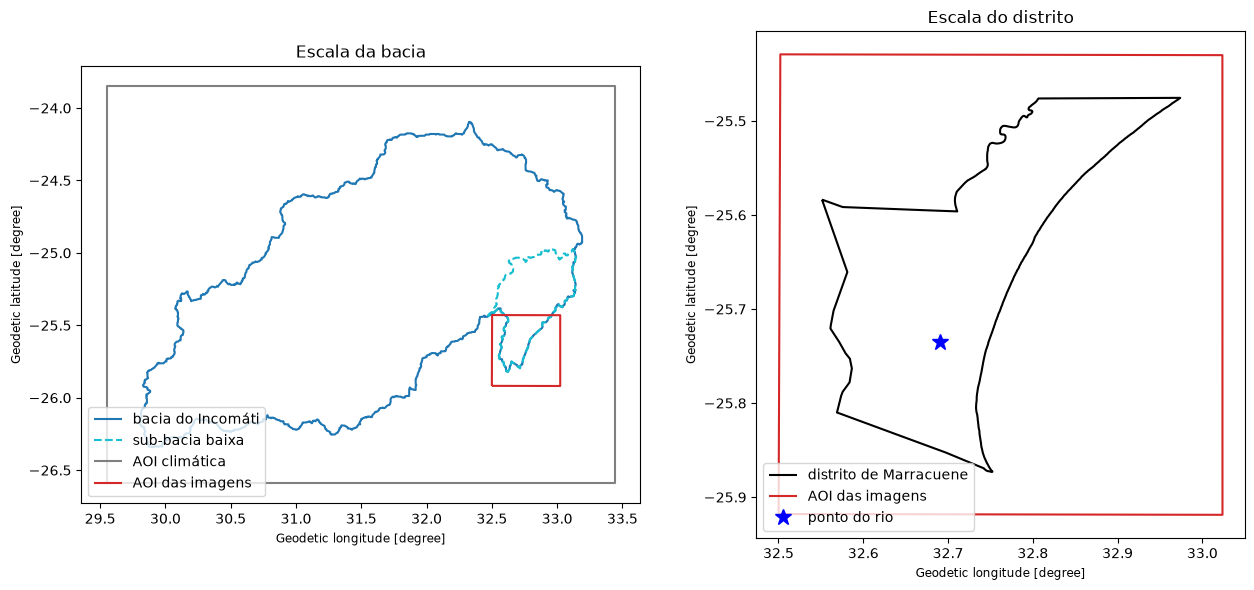

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
basin.boundary.plot(ax=axes[0], color="tab:blue", label="bacia do Incomáti")
subbasin.boundary.plot(ax=axes[0], color="tab:cyan", linestyle="--", label="sub-bacia baixa")
aoi_climate.boundary.plot(ax=axes[0], color="grey", label="AOI climática")
aoi.boundary.plot(ax=axes[0], color="tab:red", label="AOI das imagens")
axes[0].legend(loc="lower left"); axes[0].set_title("Escala da bacia")

district.boundary.plot(ax=axes[1], color="black", label="distrito de Marracuene")
aoi.boundary.plot(ax=axes[1], color="tab:red", label="AOI das imagens")
axes[1].plot(*a["river_point"], "b*", markersize=12, label="ponto do rio")
axes[1].legend(loc="lower left"); axes[1].set_title("Escala do distrito")
plt.tight_layout()

**A validar (Agostinho):** abrir o `aoi.geojson` e os ficheiros da bacia no QGIS
sobre um mapa de base. Se a AOI das imagens dever seguir a bacia baixa em vez do
retângulo do distrito, alterar `aoi.imagery_buffer_km` ou substituir a geometria
aqui - mas fazê-lo **antes** de descarregar qualquer imagem, porque o `grid.json`
fixa a grelha de píxeis de todos os ficheiros seguintes.